# Build Your Own Model: Part 3
## Finalisation and Implementation

**Malakai H | 1757692**

Week 10 | Assessment 3

---

## Introduction

This notebook finalises and implements the MCG post-match rail egress model introduced in Parts 1 and 2. As a reminder, the model tracks Jolimont, Richmond, and Flinders Street, three MCG egress supporter rail corridors, as a coupled system of ordinary differential equations over a 90-minute post-match window, following each corridor's remaining crowd $M_i(t)$, platform/gate queue $Q_i(t)$, and cumulative cleared passengers $C_i(t)$. Inflow is paced by a Gamma-shaped arrival surge and a logistic gate throttle, while outflow is capped by density-dependent boarding efficiency. Tthe design is mostly unchanged from Part 2, but I've added complete parameterisations and some tweaks here and there.

---

## Finalised model design

The causal structure below is carried over unchanged from Part 2. The design itself was already sound, so what follows is mostly about expressing the mathematics precisely enough to code against.

![diagram](diagram.png)

Blue rectangles are state variables, pink ovals are parameters/auxiliary functions, and green ovals are flow rates. Total attendance is split by corridor into initial station allocations $M_i$. Inflow fills each station's queue and is itself throttled by a balancing feedback loop (queues choke their own further entry). Outflow drains the queue but is coupled to a platform
congestion loop, where rising density degrades boarding efficiency and therefore the clearance rate.

### State variables and governing ODEs

Let the corridors be $i \in \{J, R, F\}$ (Representing Jolimont, Richmond, Flinders Sttreet respectively). For each corridor, over $t \in [0, 90]$ minutes:

* $M_i(t)$ : remaining crowd allocation for station $i$ (pax)
* $Q_i(t)$ : platform/gate queue at station $i$ (pax)
* $C_i(t)$ : cumulative passengers cleared through station $i$ by time $t$ (pax)

The system is therefore given by

$$\frac{dM_i}{dt} = -I_i(t), \text{   } \frac{dQ_i}{dt} = I_i(t) - O_i(t), \text{   } \frac{dC_i}{dt} = O_i(t)$$

with $I_i(t)$, $O_i(t)$ the inflow/outflow rates (pax/min). Total clearance at the end of the window is $\sum_i C_i(90)$.


### Inflow dynamics

$$f_i(t) = \frac{t^{k-1} e^{-t/\theta_i}}{\theta_i^{k}\,\Gamma(k)}, \qquad \theta_i = \tau_i / k$$

is the Gamma surge density governing the timing of corridor $i$'s arrivals, peaking at $t_{\text{peak},i}=\tau_i(k-1)/k$, where $\tau_i$ is the corridor's mean walking time and $k$ is a shared shape parameter. Entry into the concourse is throttled by a logistic function

$$\Psi_i(Q_i) = \frac{1}{1+\exp\big(\beta_q(Q_i - Q_{i,\text{gate\_crit}})\big)}$$

which is close to 1 when $Q_i \ll Q_{i,\text{gate\_crit}}$, $0.5$ at the critical gate queue, and chokes toward 0 once the queue is well past it. Combining the two,

$$I_i(t) = M_i(0)\cdot f_i(t) \cdot \Psi_i(Q_i)$$

I will flag that my part 2 was inconsistent about whether this should be $M_i(0)$ or $M_i(t)$. I landed on $M_i(0)$, since multiplying by the shrinking $M_i(t)$ instead left nearly half the crowd stranded even with ample capacity. Physically, $f_i(t)$ models how long it takes a fan to walk to station $i$, not a queue that waits indefinitely. A fan whose walk lands them at the gate *during* a throttled window is treated as abandoning that corridor (lift, dispersing into the park, etc) rather than waiting it out or deferring to another station (as this idea was abandoned back while drafting part 1), so any part of $M_i(0)$ the throttle blocks during the surge is effectively lost permanently, not re-attempted.

### Platform congestion and outflow

Platform density at any time $t$ is given by $D_i(t) = Q_i(t)/A_i$ ($\text{pax}/m^2$), where $A_i$ is the platform footprint. Boarding efficiency follows a Four-Parameter Logistic curve:

$$\eta(D_i) = \eta_{\min} + \frac{1-\eta_{\min}}{1+(D_i/D_{\text{crit}})^{\gamma}}$$

so efficiency sits near 1 while the platform is empty and decays toward a floor $\eta_{\min}$ once density passes the critical threshold $D_{\text{crit}}$, with $\gamma$ controlling how sharply the transition happens. Outflow is then capacity and queue limited according to

$$O_i(t) = \min\big(Q_i(t),\ C_{\text{base},i}\cdot \eta(D_i)\big), \text{   where   } C_{\text{base},i} = f_{\text{train},i}\cdot \text{Capcity}_{\text{train}}$$


### Parameters

Parameterisation for all the functions have been finalised with

| Symbol | Meaning | Value | Units |
|---|---|---|---|
| $k$ | Gamma shape | $4.0$ | NA |
| $\beta_q$ | Gate throttle sensitivity | $0.002$ | $\text{pax}^{-1}$ |
| $D_{\text{crit}}$ | Critical boarding density | $2.25$ | $\text{pax}/m^2$ |
| $\gamma$ | Boarding-efficiency curvature | $4.0$ | NA |
| $\eta_{\min}$ | Efficiency floor | $0.35$ | NA |
| $\text{Cap}_{\text{train}}$ | Train crush capacity | $1000$ | pax/train |

With physical station parameters

| Station $i$ | $\tau_i$ (min) | $Q_{i,\text{gate\_crit}}$ (pax) | $A_i$ ($m^2$) | $f_{\text{train},i}$ (trains/min) |
|---|---|---|---|---|
| Jolimont ($J$) | $7.0$ | $4000$ | $1800$ | $0.35$ |
| Richmond ($R$) | $9.0$ | $18000$ | $9000$ | $0.8$ |
| Flinders St ($F$) | $18.0$ | $25000$ | $15000$ | $1.5$ |

Walking times, gate capacities, and platform footprints follow assumed geometry estimated with google maps data. The 4PL boarding-efficiency form was estimated from Ritz et al.'s dose-response formulation (2019 [2]) (Specifically looking at their original formula, applying $\eta_{\text{min}},1$ to $c,d$ as the lower/upper asymptotes, $D_\text{crit}$ into $e$ as the inflection point, and $\gamma$ into $b$ as the slope). Values like critical densities and curves were taken from Fruin's pedestrian planning and design (1971, [1]). Frequencies estimated from peak PTV timetables


### Match scenario allocation

Corridor shares $\alpha_i$ (with $\sum_i \alpha_i = 1$) come from blending the home and away clubs' supporter geography, and I am assuming 30000 rail-bound fans per club based on an average MCG attendance of ~60000, and 40000 per club for rivalry games, according to (AFLtables)[https://afltables.com/afl/crowds/2026.html] during the 2026 season:

| Team | $\alpha_J$ | $\alpha_R$ | $\alpha_F$ |
|---|---|---|---|
| Collingwood | 0.70 | 0.15 | 0.15 |
| Hawthorn | 0.10 | 0.70 | 0.20 |
| Melbourne | 0.20 | 0.30 | 0.50 |
| Richmond | 0.22 | 0.72 | 0.06 |
| Essendon | 0.06 | 0.26 | 0.68 |
| Carlton | 0.16 | 0.16 | 0.68 |
| St Kilda | 0.06 | 0.68 | 0.26 |
| Geelong | 0.06 | 0.33 | 0.61 |

For a fixture between teams $a$ and $b$ with equal attendance each, $\alpha_i = \tfrac{1}{2}(\alpha_{i,a}+\alpha_{i,b})$, and $M_i(0) = \alpha_i \cdot N_{\text{total}}$. Teams that were parameterised play at least one home game at the MCG.

---

## Implementation

The implementation is as follows, with each function mirroring one piece of the maths above.

The import functions:


In [64]:
import numpy as np
import matplotlib.pyplot as plt
from math import exp, gamma as gamma_function, isfinite

Basic math functions and validators taken directly from part 2:

In [65]:
def _require_positive(value: float,
                      name: str
                     ) -> None:
    if not isfinite(value) or value <= 0:
        raise ValueError(f"{name} must be a finite positive number") # catches NaNs, zeros, negatives in one go

def gamma_density(time: float,
                  shape: float,
                  scale: float
                 ) -> float:
    _require_positive(shape, "shape")
    _require_positive(scale, "scale") # validate given parameters

    if time < 0: # nobody arrives before the final siren
        return 0.0

    density: float = time ** (shape - 1) * exp(-time / scale) / (scale**shape * gamma_function(shape)) # gamma func

    return density

def queue_throttle(queue: float,
                   gate_capacity: float,
                   sensitivity: float
                  ) -> float:
    _require_positive(gate_capacity, "gate_capacity")
    _require_positive(sensitivity, "sensitivity")

    if queue < 0: # cant use _require_positive since queue starts AT zero
        raise ValueError("queue must not be negative")

    argument = sensitivity * (queue - gate_capacity) # split the two exp forms below to dodge overflow for fat numbers

    if argument >= 0:
        throttle: float = exp(-argument) / (1.0 + exp(-argument))
    else:
        throttle: float = 1.0 / (1.0 + exp(argument))

    return throttle

Parameterisations/Constants:

In [66]:
# Station and global model parameters, straight from the tables, using dictionaries for ease of reading data later
STATION_NAMES = ["J", "R", "F"]

STATIONS = {
    "J": {"tau": 7.0,  "gate_crit": 4000.0,  "area": 1800.0,  "f_train": 0.4},
    "R": {"tau": 9.0,  "gate_crit": 18000.0, "area": 9000.0,  "f_train": 0.8},
    "F": {"tau": 18.0, "gate_crit": 25000.0, "area": 15000.0, "f_train": 1},
}

MODEL = {
    "shape": 4.0,
    "beta_q": 0.002,
    "d_crit": 2.25,
    "gamma_exp": 4.0,
    "eta_min": 0.35,
    "train_capacity": 1000.0,
}

# Corridor demographic shares, from the table in 1.5
TEAM_SHARES = {
    "Collingwood": (0.70, 0.15, 0.15),
    "Hawthorn":    (0.10, 0.70, 0.20),
    "Melbourne":   (0.20, 0.30, 0.50),
    "Richmond":    (0.22, 0.72, 0.06),
    "Essendon":    (0.06, 0.26, 0.68),
    "Carlton":     (0.16, 0.16, 0.68),
    "St Kilda":    (0.06, 0.68, 0.26),
    "Geelong":     (0.06, 0.33, 0.61),
}


Efficiency and flow functions:

In [67]:
def boarding_efficiency(density: float,
                        d_crit: float,
                        gamma_exp: float,
                        eta_min: float
                       ) -> float:
    _require_positive(d_crit, "d_crit")
    _require_positive(gamma_exp, "gamma_exp")
    if not 0 < eta_min <= 1:
        raise ValueError("eta_min must be greater than 0 and at most 1")
    if density < 0:
        raise ValueError("density must not be negative")

    efficiency: float = eta_min + (1.0 - eta_min) / (1.0 + (density / d_crit) ** gamma_exp)   # 4PL curve func

    return efficiency

def inflow_rate(time: float,
                queue: float,
                station_allocation: float,
                shape: float,
                scale: float,
                gate_capacity: float,
                sensitivity: float
               ) -> float:
    _require_positive(station_allocation, "station_allocation")

    inflow: float = station_allocation * gamma_density(time, shape, scale) * queue_throttle(queue, gate_capacity, sensitivity) # inflow func

    return inflow

def outflow_rate(queue: float,
                 platform_area: float,
                 base_capacity: float,
                 d_crit: float,
                 gamma_exp: float,
                 eta_min: float
                ) -> float:
    _require_positive(platform_area, "platform_area")
    _require_positive(base_capacity, "base_capacity")
    if queue < 0:
        raise ValueError("queue must not be negative")

    density = queue / platform_area
    capacity = base_capacity * boarding_efficiency(density, d_crit, gamma_exp, eta_min) # cap eqn
    outflow: float = min(queue, capacity) # ensure we dont clear pax that aren't on the platform

    return outflow


Allocation percentage and number calculation function:

In [68]:
def match_allocation(home_team: str,
                     away_team: str,
                     attendance_each: float = 30000.0,
                     rivalry: bool = False
                    ) -> tuple[float, dict[str, float]]:
    _require_positive(attendance_each, "attendance_each")
    if home_team not in TEAM_SHARES or away_team not in TEAM_SHARES:
        raise ValueError("unrecognised team name")

    if not rivalry:
      each = attendance_each
    else:
      each = attendance_each + 10000 # rivalry fixtures draw extra fans
    total = 2.0 * each

    home_alpha = TEAM_SHARES[home_team]
    away_alpha = TEAM_SHARES[away_team]

    shares = {}
    for idx, name in enumerate(STATION_NAMES):
        shares[name] = (each * home_alpha[idx] + each * away_alpha[idx]) / total # attendance-weighted blend

    return total, shares


Final implemented simulator function:

In [69]:
def simulate_egress(attendance: float,
                    shares: dict[str, float],
                    stations: dict[str, dict[str, float]] = STATIONS,
                    model: dict[str, float] = MODEL,
                    duration: float = 90.0,
                    dt: float = 0.1
                   ):
    _require_positive(attendance, "attendance")
    _require_positive(duration, "duration")
    _require_positive(dt, "dt")
    if abs(sum(shares.values()) - 1.0) > 1e-9:
        raise ValueError("shares must sum to 1")

    n_steps = int(round(duration / dt))
    n_stations = len(STATION_NAMES) # should be 3, keeping it flexy for future logistic models

    times = np.linspace(0.0, duration, n_steps + 1)
    M = np.zeros((n_steps + 1, n_stations)) # remaining allocation
    Q = np.zeros((n_steps + 1, n_stations)) # platform/gate queue
    C = np.zeros((n_steps + 1, n_stations)) # cleared

    for idx, name in enumerate(STATION_NAMES): # learned this one from a project i did just last week, how neat!
        M[0, idx] = attendance * shares[name] # set initial values for each station (np cant understand string names)

    # clipping each flow keeps the loop from throwing dumb errors because its trying to move non existent pax...
    for step in range(n_steps):
        t = times[step]
        for idx, name in enumerate(STATION_NAMES): # does this calc for all stations
            station = stations[name] # sets current station
            scale = station["tau"] / model["shape"] # theta_i = tau_i / k
            base_capacity = station["f_train"] * model["train_capacity"] # C_base,i

            inflow = inflow_rate(t, Q[step, idx], M[0, idx], model["shape"], scale,
                                  station["gate_crit"], model["beta_q"]) # inflow + passing details
            outflow = outflow_rate(Q[step, idx], station["area"], base_capacity,
                                    model["d_crit"], model["gamma_exp"], model["eta_min"]) # outflow + passing details

            incoming = min(M[step, idx], inflow * dt) # clamp so a step can't move more pax than actually exist
            departing = min(Q[step, idx] + incoming, outflow * dt) # same

            M[step + 1, idx] = M[step, idx] - incoming # sets next M value
            Q[step + 1, idx] = Q[step, idx] + incoming - departing # next Q value
            C[step + 1, idx] = C[step, idx] + departing # next C value

    return times, M, Q, C 


---

## Function testing and verification

Sanity check tests for each function/guards before we test the whole thing. (I stick to spot tests here, since large tests will be done across the whole model later in this assignment :) )


In [70]:
print("Gamma density at Jolimont's peak (t = 5.25 min):", gamma_density(5.25, 4.0, 1.75))
print("Gamma density at t = 60 min (long after the surge):", gamma_density(60.0, 4.0, 1.75))
print()

print("Throttle at Q = 0 (expect ~1.0):", queue_throttle(0.0, 4000.0, 0.002))
print("Throttle at Q = gate_crit (expect 0.5):", queue_throttle(4000.0, 4000.0, 0.002))
print("Throttle at Q >> gate_crit (expect ~0.0):", queue_throttle(9000.0, 4000.0, 0.002))
print()

print("Boarding efficiency at D ~ 0 (expect ~1.0):", boarding_efficiency(0.0001, 2.25, 4.0, 0.35))
print("Boarding efficiency at D = D_crit (expect ~0.675):", boarding_efficiency(2.25, 2.25, 4.0, 0.35))
print("Boarding efficiency at D >> D_crit (expect -> eta_min = 0.35):", boarding_efficiency(20.0, 2.25, 4.0, 0.35))


Gamma density at Jolimont's peak (t = 5.25 min): 0.128023890088793
Gamma density at t = 60 min (long after the surge): 4.943719068916771e-12

Throttle at Q = 0 (expect ~1.0): 0.9996646498695336
Throttle at Q = gate_crit (expect 0.5): 0.5
Throttle at Q >> gate_crit (expect ~0.0): 4.5397868702434395e-05

Boarding efficiency at D ~ 0 (expect ~1.0): 1.0
Boarding efficiency at D = D_crit (expect ~0.675): 0.675
Boarding efficiency at D >> D_crit (expect -> eta_min = 0.35): 0.3501041007567123


In [71]:
# Validation guards
for label, func in [
    ("negative queue", lambda: queue_throttle(-1.0, 4000.0, 0.002)),
    ("zero gate_capacity", lambda: queue_throttle(100.0, 0.0, 0.002)),
    ("eta_min out of range", lambda: boarding_efficiency(1.0, 2.25, 4.0, 1.5)),
]:
    try:
        func()
        print(label, "-> NO ERROR RAISED")
    except ValueError as err:
        print(label, "-> correctly raised:", err) # cheers


negative queue -> correctly raised: queue must not be negative
zero gate_capacity -> correctly raised: gate_capacity must be a finite positive number
eta_min out of range -> correctly raised: eta_min must be greater than 0 and at most 1


In [72]:
# M + Q + C should equal the initial allocation at all t, since nothing in the model creates or destroys passengers
attendance, shares = match_allocation("Richmond", "Hawthorn")
times, M, Q, C = simulate_egress(attendance, shares)

total_mass = M + Q + C
drift = np.max(np.abs(total_mass - total_mass[0])) # check for missing passengers who have been doomed
print(f"Max mass-conservation drift over the 90 min window: {drift:.2e} pax (should be ~0)")
print(f"Total cleared by t=90 (Richmond v Hawthorn): {C[-1].sum():.0f} / {attendance:.0f} pax")
print(f"Breakdown by station: J={C[-1,0]:.0f}, R={C[-1,1]:.0f}, F={C[-1,2]:.0f}")

Max mass-conservation drift over the 90 min window: 5.82e-11 pax (should be ~0)
Total cleared by t=90 (Richmond v Hawthorn): 45479 / 60000 pax
Breakdown by station: J=7828, R=29851, F=7800


As we can see, each of the functions behave as expected according to our sanity check spot tests (again dont worry, more rigorous stuff coming next!). The Gamma surge peaks around Jolimont's expected $5.25$ min mark and is essentially zero an hour later, the throttle gives free flow, half-capacity, and near-total choking at the three queue regimes it was built for, and boarding efficiency smoothly interpolates between $1$ and $\eta_{\min}$ around $D_{\text{crit}}$. 

All three invalid-input cases raise `ValueError` as intended rather than producing nonsense silently, and the coupled simulation conserves total passengers. 

---

## Results

Running the finalised model and graphing it on an example baseline fixture (Richmond v Hawthorn has a heavy Richmond bias) and then running it against a fixture with very different corridor demographics (Geelong v Essendon has a heavy Flinders bias) to check the model actually has some contrast the way the design intends it to.

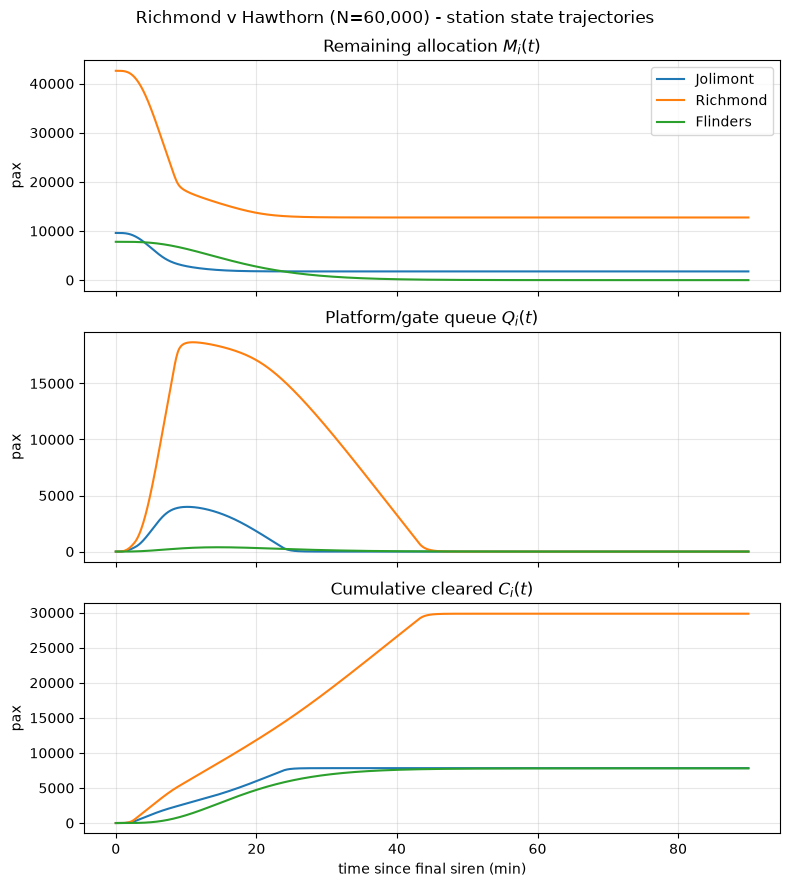

In [76]:
attendance, shares = match_allocation("Richmond", "Hawthorn")
times, M, Q, C = simulate_egress(attendance, shares)

colors = {"J": "tab:blue", "R": "tab:orange", "F": "tab:green"}
labels = {"J": "Jolimont", "R": "Richmond", "F": "Flinders"}

fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
state_arrays = [M, Q, C]
titles = ["Remaining allocation $M_i(t)$", "Platform/gate queue $Q_i(t)$", "Cumulative cleared $C_i(t)$"]
for ax, arr, title in zip(axes, state_arrays, titles):
    for idx, name in enumerate(STATION_NAMES):
        ax.plot(times, arr[:, idx], color=colors[name], label=labels[name])
    ax.set_ylabel("pax")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time since final siren (min)")
fig.suptitle("Richmond v Hawthorn (N=60,000) - station state trajectories")
fig.tight_layout()
plt.show()


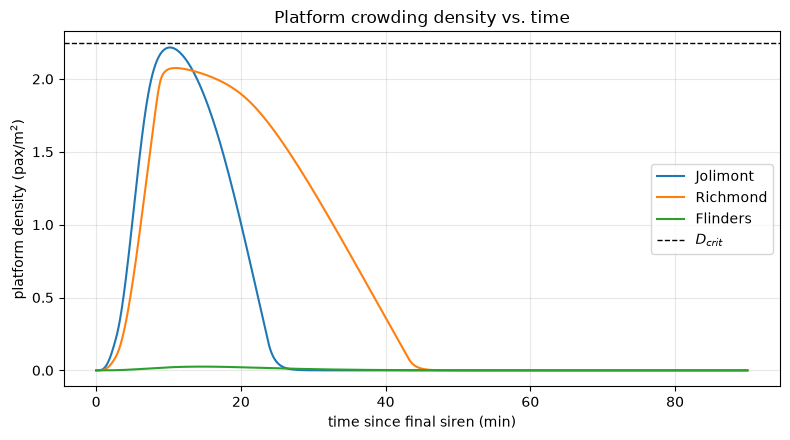

In [77]:
fig2, ax2 = plt.subplots(figsize=(8, 4.5))
for idx, name in enumerate(STATION_NAMES):
    density = Q[:, idx] / STATIONS[name]["area"]
    ax2.plot(times, density, color=colors[name], label=labels[name])
ax2.axhline(MODEL["d_crit"], color="k", linestyle="--", linewidth=1, label="$D_{crit}$")
ax2.set_xlabel("time since final siren (min)")
ax2.set_ylabel("platform density (pax/m$^2$)")
ax2.set_title("Platform crowding density vs. time")
ax2.legend()
ax2.grid(alpha=0.3)
fig2.tight_layout()
plt.show()


Richmond v Hawthorn: shares={'J': 0.16, 'R': 0.71, 'F': 0.13}, total cleared=45479/60000
Geelong v Essendon: shares={'J': 0.06, 'R': 0.295, 'F': 0.645}, total cleared=59997/60000


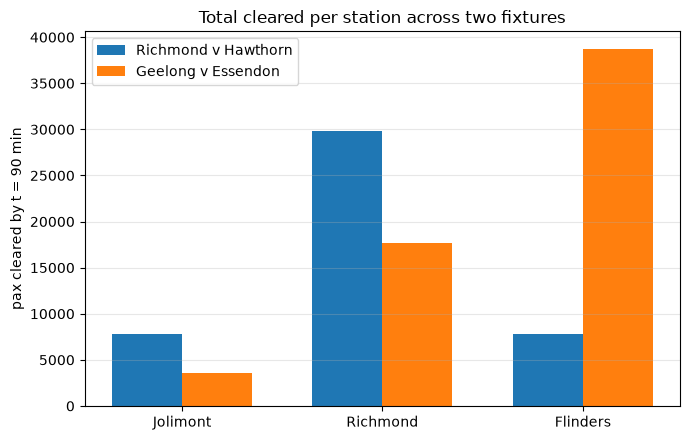

In [78]:
# compare a Richmond heavy fixture against a Flinders heavy one
scenarios = [("Richmond", "Hawthorn"), ("Geelong", "Essendon")]

results = {}
for home, away in scenarios: # runs for each of the scenarios
    att, sh = match_allocation(home, away)
    t_s, M_s, Q_s, C_s = simulate_egress(att, sh)
    results[(home, away)] = (att, C_s[-1])
    print(f"{home} v {away}: shares={sh}, total cleared={C_s[-1].sum():.0f}/{att:.0f}")

fig3, ax3 = plt.subplots(figsize=(7, 4.5))
width = 0.35
x = np.arange(len(STATION_NAMES))
for i, (key, (att, cleared)) in enumerate(results.items()):
    ax3.bar(x + i * width, cleared, width, label=f"{key[0]} v {key[1]}")
ax3.set_xticks(x + width / 2)
ax3.set_xticklabels([labels[n] for n in STATION_NAMES])
ax3.set_ylabel("pax cleared by t = 90 min")
ax3.set_title("Total cleared per station across two fixtures")
ax3.legend()
ax3.grid(alpha=0.3, axis="y")
fig3.tight_layout()
plt.show()


Richmond bottlenecks in the baseline fixture, as its its 71% share puts makes $Q_R$ overshoots gate capacity (peaking near $t=15$) and $\Psi_R$ drops to about $0.47$. The gate reopens by $t=20$ ($\Psi_R \approx 0.96$), but the surge has mostly passed by then, so little demand is left. Almost a quarter of Richmond’s allocation never enter, shown as the plateau in $M_R(t)$ after $t \approx 30$. Remember, these aren;t people still queueing, but people whose walking-time coincided with peak congestion and were treated as having left the corridor. Jolimont and Flinders clear almost fully. The contrast fixture (Geelong v Essendon) confirms this is demand-driven, and that spreading load more towards the bigger station clears $59997/60000$ (99.96%) with essentially nobody stranded.

## Assumptions, limitations, and validity notes

The model is sound (it does what it's built to do), but there are some major assumptions I make.

- **Stranded demand.** As discussed, the crowd that never gets admitted during the surge window simply stays in $M_i$ forever. In reality some of those fans would likely walk to a different station instead (Part 1's original causal loop sketch flagged this possibility and then set it aside as out of scope). This model still does not capture cross-corridor rerouting or retries as it over-complicates the concept.
- **Independent corridors.** $J$, $R$, and $F$ evolve independently with no shared concourse or city-loop congestion between them, even though Flinders and the city loop are physically connected to every other with some transfers in reality.
- **Homogeneous dynamics.** The same generalised throttle sensitivity $\beta_q$, density exponent $\gamma$, and efficiency floor $\eta_{\min}$ are applied at all three stations, even though they have different physical layouts.
- **Time steps.** A fixed step size with bounded flows was used. While the conservation check shows its it's numerically well-behaved at this step size for these parameters (given my numerous checks and verification steps), that was verified empirically rather than proven, and there might be edge cases which break the simulation.


## References

[1] Fruin, J (1971). *Pedestrian Planning and Design*. Elevator World. Available at: https://cloud.kaiwave.dev/index.php/s/go3ynXKt6s9CKzF

[2] Ritz, C., Baty, F., Streibig, J. C., & Gerhard, D. (2019). *Dose-Response Analysis Using R*.
The R Journal, 11(2). Available at: https://journals.plos.org/plosone/article/file?id=10.1371/journal.pone.0146021&type=printable

---

Thanks!
